# Exploratory Data Analysis (EDA)

This notebook performs Exploratory Data Analysis on a tabular dataset.

The purpose of EDA is to understand the dataset, identify data-quality issues, explore feature distributions, and discover relationships between variables.

### Topics covered
1. Dataset overview
2. Column information
3. Missing-value analysis
4. Numerical feature analysis
5. Categorical feature analysis
6. Outlier detection
7. Correlation analysis
8. Feature relationships

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Locate project root automatically
current_path = Path.cwd().resolve()
project_root = None

for path in [current_path, *current_path.parents]:
    if (path / "modules").is_dir():
        project_root = path
        break

if project_root is None:
    raise FileNotFoundError("Could not locate the AutoML-Studio project root.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import modules.data_loader as data_loader
import modules.eda as eda

print("Project root:", project_root)

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Project root: C:\Users\PMLS\Documents\Coding\System-7-Internship\AutoML-Studio


In [2]:
sample_path = project_root / "sample_data" / "student-mat.csv"

if not sample_path.exists():
    raise FileNotFoundError(f"Dataset not found: {sample_path}")

df = data_loader.load_csv(sample_path)
data_loader.validate_dataset(df)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
overview = eda.get_dataset_overview(df)
display(overview)

{'Total Rows': 395,
 'Total Columns': 33,
 'Missing Values': 0,
 'Duplicate Rows': 0,
 'Memory Usage (KB)': np.float64(122.62)}

In [4]:
column_summary = eda.get_column_summary(df)
display(column_summary)

print("\nData Types:")
display(df.dtypes.to_frame(name="Data Type"))

,Data Type,Missing Values,Unique Values
school,str,0,2
sex,str,0,2
age,int64,0,8
address,str,0,2
famsize,str,0,2
Pstatus,str,0,2
Medu,int64,0,5
Fedu,int64,0,5
Mjob,str,0,5
Fjob,str,0,5



Data Types:


,Data Type
school,str
sex,str
age,int64
address,str
famsize,str
Pstatus,str
Medu,int64
Fedu,int64
Mjob,str
Fjob,str


In [5]:
missing_summary = eda.get_missing_values_summary(df)
display(missing_summary)

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

if not missing_counts.empty:
    plt.figure(figsize=(10, 5))
    missing_counts.plot(kind="bar")

    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

,Missing Values,Missing Percentage
school,0,0.0
sex,0,0.0
age,0,0.0
address,0,0.0
famsize,0,0.0
Pstatus,0,0.0
Medu,0,0.0
Fedu,0,0.0
Mjob,0,0.0
Fjob,0,0.0


No missing values found.


In [6]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()

print("Numerical Columns:", numeric_columns)

if numeric_columns:
    numeric_stats = eda.get_numeric_statistics(df)
    display(numeric_stats)
else:
    print("No numerical columns found.")

Numerical Columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


Selected Column: age


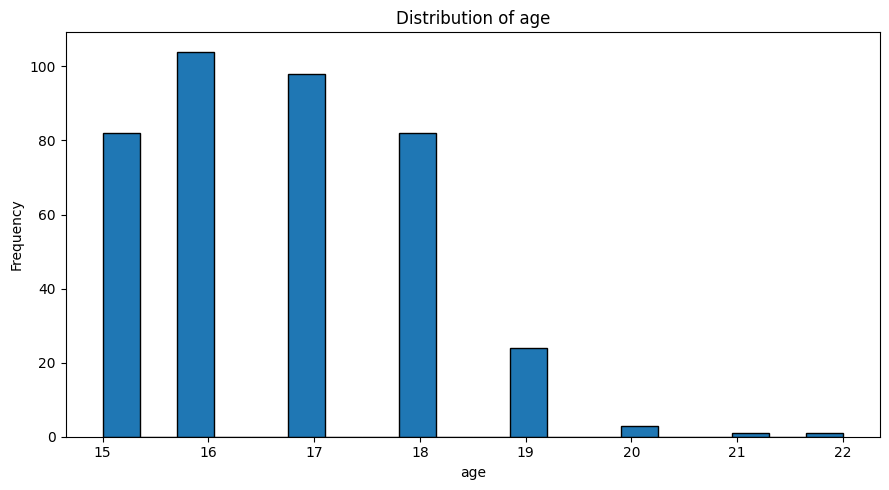

In [7]:
if numeric_columns:
    selected_column = numeric_columns[0]

    print("Selected Column:", selected_column)

    eda.plot_numeric_distribution(df, selected_column)
    plt.show()

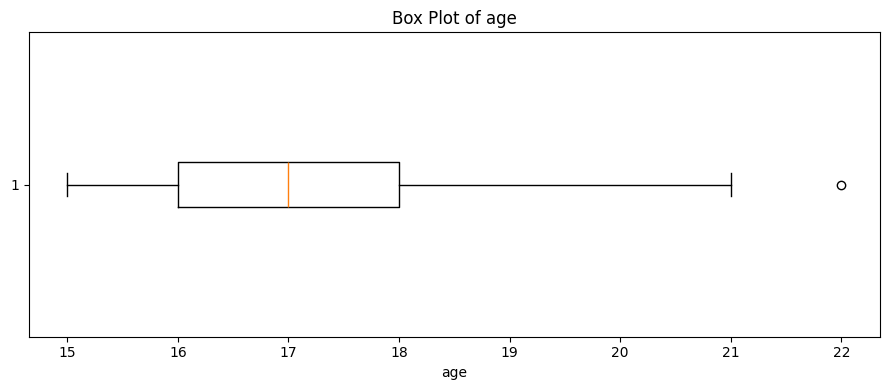

In [8]:
if numeric_columns:
    eda.plot_numeric_boxplot(df, selected_column)
    plt.show()

In [9]:
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Categorical Columns:", categorical_columns)

if categorical_columns:
    categorical_stats = eda.get_categorical_statistics(df)
    display(categorical_stats)
else:
    print("No categorical columns found.")

Categorical Columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


{'school': school
 GP    349
 MS     46
 Name: count, dtype: int64,
 'sex': sex
 F    208
 M    187
 Name: count, dtype: int64,
 'address': address
 U    307
 R     88
 Name: count, dtype: int64,
 'famsize': famsize
 GT3    281
 LE3    114
 Name: count, dtype: int64,
 'Pstatus': Pstatus
 T    354
 A     41
 Name: count, dtype: int64,
 'Mjob': Mjob
 other       141
 services    103
 at_home      59
 teacher      58
 health       34
 Name: count, dtype: int64,
 'Fjob': Fjob
 other       217
 services    111
 teacher      29
 at_home      20
 health       18
 Name: count, dtype: int64,
 'reason': reason
 course        145
 home          109
 reputation    105
 other          36
 Name: count, dtype: int64,
 'guardian': guardian
 mother    273
 father     90
 other      32
 Name: count, dtype: int64,
 'schoolsup': schoolsup
 no     344
 yes     51
 Name: count, dtype: int64,
 'famsup': famsup
 yes    242
 no     153
 Name: count, dtype: int64,
 'paid': paid
 no     214
 yes    181
 Name: co

Selected Column: school


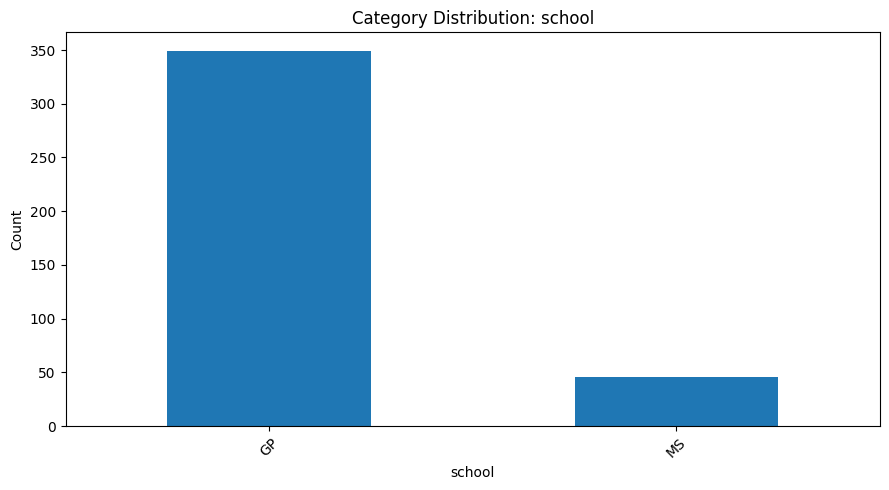

In [10]:
if categorical_columns:
    selected_category = categorical_columns[0]

    print("Selected Column:", selected_category)

    eda.plot_categorical_distribution(df, selected_category)
    plt.show()

In [11]:
outlier_summary = eda.get_outlier_summary(df)
display(outlier_summary)

,Outlier Count,Lower Bound,Upper Bound
age,1.0,13.0,21.0
Medu,0.0,-1.0,7.0
Fedu,2.0,0.5,4.5
traveltime,8.0,-0.5,3.5
studytime,27.0,-0.5,3.5
failures,83.0,0.0,0.0
famrel,26.0,2.5,6.5
freetime,19.0,1.5,5.5
goout,0.0,-1.0,7.0
Dalc,18.0,-0.5,3.5


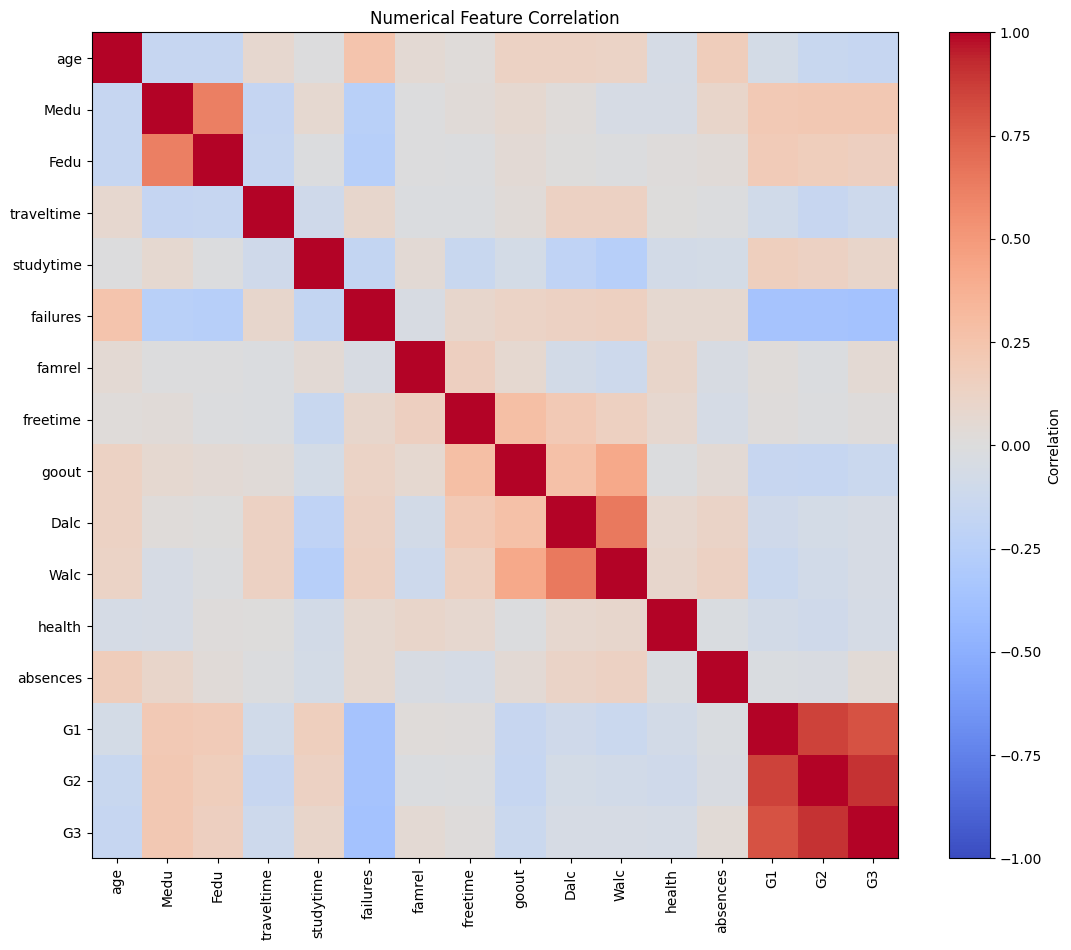

In [12]:
if len(numeric_columns) >= 2:
    eda.plot_correlation_heatmap(df)
    plt.show()
else:
    print("At least two numerical columns are required.")

Relationship: age vs Medu


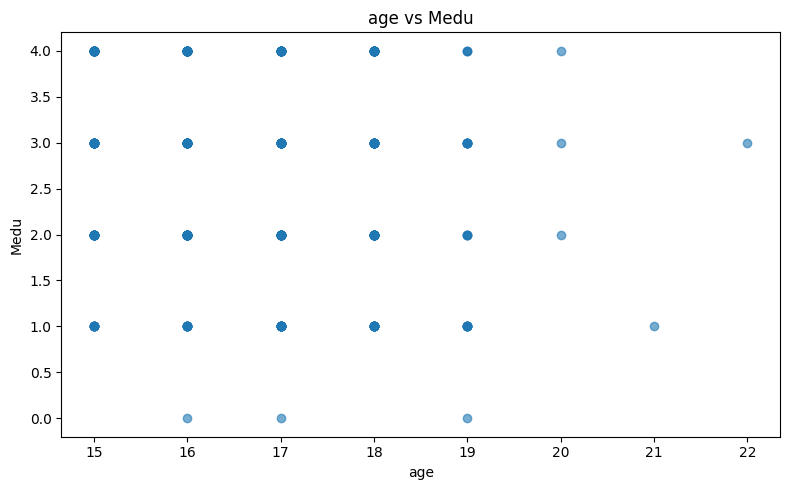

In [13]:
if len(numeric_columns) >= 2:
    x_column = numeric_columns[0]
    y_column = numeric_columns[1]

    print(f"Relationship: {x_column} vs {y_column}")

    eda.plot_scatter_relationship(df, x_column, y_column)
    plt.show()
else:
    print("At least two numerical columns are required.")

# EDA Observations

After completing the analysis, record your observations:

1. Which columns contain missing values?
2. Which numerical features have unusual distributions?
3. Which columns contain potential outliers?
4. Which categorical features have the most distinct values?
5. Which numerical features appear correlated?
6. Are there any data-quality issues that need attention?

### Conclusion

EDA helps us understand the dataset before applying preprocessing and machine learning algorithms.

The next step is to prepare the dataset for model training by handling missing values, encoding categorical variables, and scaling numerical features.

See `preprocessing.ipynb` for the next stage.